In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [ ]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('images', filename)
    os.rename(filename, dest)
    print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Saving input.jpg to input.jpg
File 'input.jpg' Moved To 'images/input.jpg'.

Contents Of Images Folder:
['input.jpg']


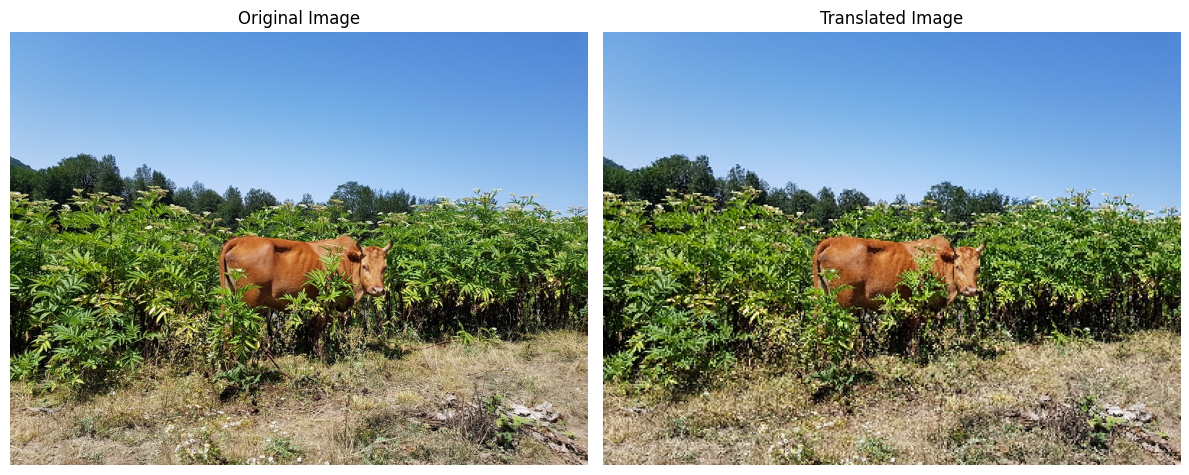

In [ ]:
image = cv2.imread('images/input.jpg')

height, width = image.shape[:2]

T = np.float32([[0.5, 0, 0], [0, 0.5, 0]])

img_translation = cv2.warpAffine(image, T, (width // 2, height // 2))

plt.figure(figsize=(12, 7))

plt.subplot(1, 2, 1)
plt.imshow(image[..., ::-1])
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_translation[..., ::-1])
plt.title('Translated Image')
plt.axis('off')

plt.tight_layout()
plt.show()

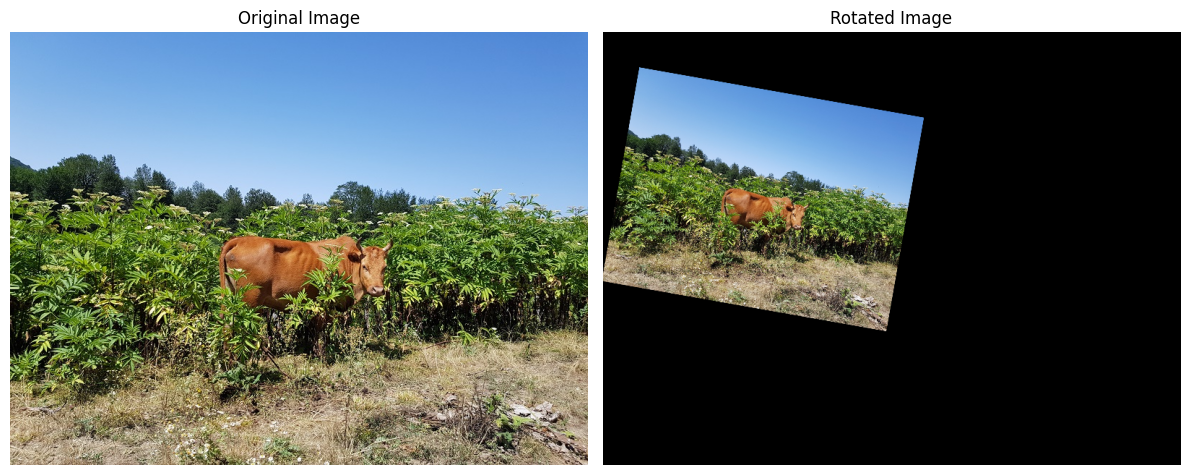

In [ ]:
rotation_amount = 10

theta = rotation_amount * np.pi / 180.0

image = cv2.imread('images/input.jpg')

height, width = image.shape[:2]

T1 = np.float32([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
T2 = np.float32([[0.5, 0], [0, 0.5]])
T = np.matmul(T2, T1)
final_T = np.ones((2, 3)) * 50
final_T[:, :-1] = T

img_rotation = cv2.warpAffine(image, final_T, (width, height))

plt.figure(figsize=(12, 7))

plt.subplot(1, 2, 1)
plt.imshow(image[..., ::-1])
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_rotation[..., ::-1])
plt.title('Rotated Image')
plt.axis('off')

plt.tight_layout()
plt.show()

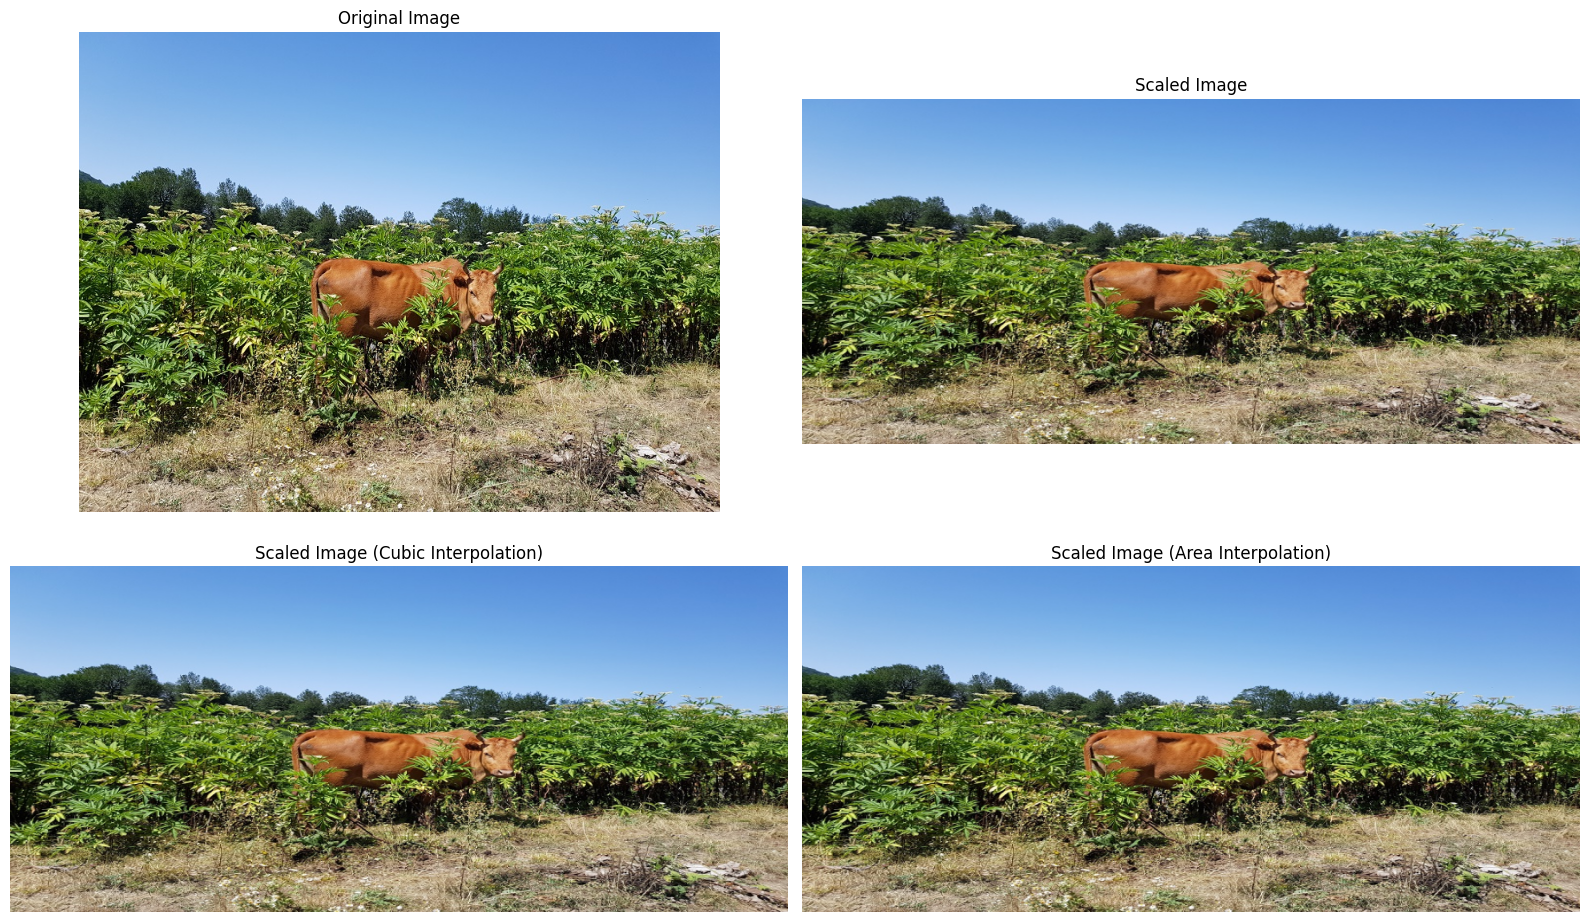

In [ ]:
image = cv2.imread('images/input.jpg')

image_scaled = cv2.resize(image, None, fx=0.75, fy=0.75)
image_scaled = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
image_scaled = cv2.resize(image, (900, 400), interpolation=cv2.INTER_AREA)

plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(image[..., ::-1])
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(image_scaled[..., ::-1])
plt.title('Scaled Image')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(image_scaled[..., ::-1])
plt.title('Scaled Image (Cubic Interpolation)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(image_scaled[..., ::-1])
plt.title('Scaled Image (Area Interpolation)')
plt.axis('off')

plt.tight_layout()
plt.show()